# HistDiff Feature Selection

In this note book I will be going through the feature selection process

In [2]:
import pandas as pd
import os

from matplotlib import pyplot as plt

## We will use the cleaned data for feature reduction ultimately giving us a new datset

In [23]:
# histdiff_outputs = "/home/derfelt/PartchLabFiles/Circadian Rhythms/Pilot Study/HistDiff Outputs"
histdiff_outputs = '/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs'

for file in os.listdir(histdiff_outputs):
    curr_file_path = os.path.join(histdiff_outputs, file)
    print(curr_file_path)

/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_24h_per2ref.csv
/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_66h_bmal1ref.csv
/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_72h_bmal1ref.csv
/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_24h_bmal1ref.csv
/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_72h_per2ref.csv
/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_66h_per2ref.csv


# cols to remove

`["Row", "Column"]`

In [24]:
exclude_cols = ["Row", "Column", 'Timepoint']
id_cols = ['id']
# df = pd.read_csv("/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/HistDiff Outputs/HistDiff_results_24h_per2ref.csv", index_col=id_cols, usecols=lambda column: column not in exclude_cols)

df_list = []
for file in os.listdir(histdiff_outputs):
    curr_file_path = os.path.join(histdiff_outputs, file)
    df = pd.read_csv(curr_file_path, index_col=id_cols, usecols=lambda col: col not in exclude_cols)
    df_list.append(df)

dfs = pd.concat(df_list)

dfs

,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Bright,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Dark,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Edge,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Hole,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Ridge,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Saddle,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Spot,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SER-Valley,Nuclei - Cell Region Alexa 488 shortened (global) Axial Length Ratio SP-Filter,...,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Bright,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Dark,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Edge,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Hole,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Ridge,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Saddle,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Spot,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SER-Valley,Nuclei - Ring Region TMR/AF555 Rabbitts (global) Threshold Compactness 60% SP-Filter,Nuclei - Ring Region Width [µm]
id,,,,,,,,,,,,,,,,,,,,,
A1,-0.000844,-0.001064,-0.000624,-0.000682,-0.000241,-0.001145,-0.000727,-0.000532,-0.000715,-0.000978,...,0.001131,-0.001229,-0.001530,-0.001728,0.007425,0.007308,0.000470,-0.001303,-0.003171,-0.007789
A10,-0.000493,-0.001611,-0.000793,-0.000614,-0.000823,-0.001678,-0.000606,-0.001313,-0.000932,-0.000690,...,0.002082,-0.000621,-0.000756,-0.001000,0.009313,0.004809,0.000548,-0.001828,-0.001253,-0.006147
A11,0.000265,-0.000468,-0.000125,-0.000299,-0.000173,-0.000625,-0.000153,-0.000293,-0.000309,-0.000406,...,0.003224,-0.000652,-0.001110,-0.001370,0.012679,0.005439,0.000510,-0.001392,-0.000939,-0.001891
A12,0.000216,-0.000455,0.000152,-0.000294,-0.000195,-0.000500,-0.000095,-0.000233,0.000151,0.000249,...,0.003523,-0.000569,-0.001288,-0.002234,0.017679,0.005039,0.000833,-0.001765,-0.001276,-0.003238
A13,-0.000531,-0.000836,-0.000536,-0.000444,-0.000457,-0.000949,-0.000328,-0.000597,-0.000540,-0.000924,...,0.002718,-0.000658,-0.000687,-0.001868,0.011305,0.004035,0.000835,-0.001475,-0.001303,-0.001038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P5,-0.002498,-0.003720,-0.002413,-0.002720,-0.002628,-0.003573,-0.002829,-0.003243,-0.002091,-0.002630,...,-0.000062,-0.001384,0.005689,-0.000589,0.000797,-0.000888,-0.000156,-0.000129,0.000125,-0.003038
P6,-0.003032,-0.003247,-0.002104,-0.001870,-0.002538,-0.003317,-0.002725,-0.002230,-0.001906,-0.002928,...,0.000246,-0.000781,0.006243,-0.000419,0.001096,0.000370,0.000450,-0.000828,0.000128,-0.001242
P7,-0.001849,-0.001870,-0.001467,-0.001235,-0.001712,-0.002037,-0.001425,-0.001697,-0.001490,-0.002118,...,0.000839,-0.000604,0.007864,0.000093,0.000637,0.000553,0.000410,-0.000647,-0.000317,-0.001157


In [25]:
outDir = '/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/Feature Reduction/combined_datasets'
outFile = os.path.join(outDir, "combinedHistDiffOuts.csv")

dfs.to_csv(outFile)

Next run the output in `featureReducer.py`

# `FeatureReducer.py` results

In [34]:
feature_results = '/Users/dterciano/Desktop/PartchLabFiles/CircadianRhythms/PilotStudy/Feature Reduction/results.csv'
feature_results = pd.read_csv(feature_results, index_col=0)

feature_results

,Extensive (5880 features),Standard (3760 features),Basic (2170 features)
thresholds,,,
0.75,474,411,245
0.80,805,644,379
0.85,1247,951,552
0.90,2030,1487,855
0.95,3271,2283,1312
0.99,4920,3284,1948


In [39]:
def plot_feat_counts(df: pd.DataFrame) -> None:
    ax = df.plot(marker='x', color='blue', linestyle='-', markerfacecolor='red', markeredgecolor='red', markersize=8)
    ax.set_xlabel('Correlation Threshold')
    ax.set_ylabel('Features Kept')
    ax.set_title('Feature Reduction vs. Correlation Threshold')
    ax.grid(True)
    plt.tight_layout()
    plt.show()

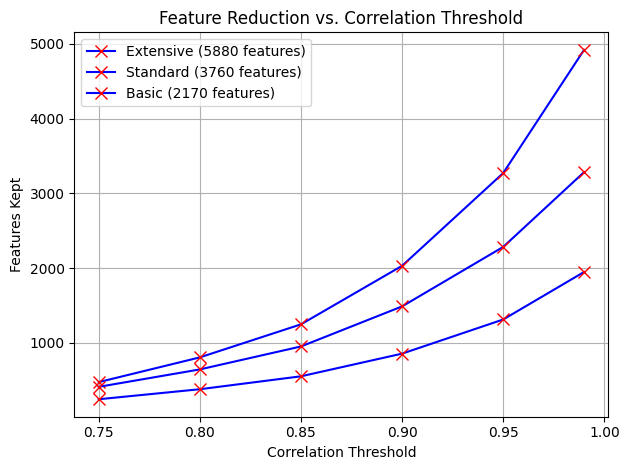

In [40]:
plot_feat_counts(feature_results)

# Results

Based on the above plot, it looks like the numbers of features kept baloons after `0.85`

When it gets to `0.90`, we can see that the number features kept rapidly increases! By using
the 0.85 threshold, we can see that most of the redundant features are being excluded.

# Number of features to use: `1247`